In [14]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import jeulib as jl
import joueurlib as jlib

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# TP Min Max

#### 1. Commencez par jouer une partie contre vous même pour vérifier que le jeu marche bien chez vous.

In [15]:
game_instance = jl.Jeu()
game_instance.demarrer()

Quel type de joueur souhaitez vous sélectionner pour noir ? Les possibilités sont :
1  : <class 'joueurlib.Humain'>
2  : <class 'joueurlib.Random'>
3  : <class 'joueurlib.Minmax'>
4  : <class 'joueurlib.AlphaBeta'>
Quel type de joueur souhaitez vous sélectionner pour blanc ?
Les possibilités sont :
1  : <class 'joueurlib.Humain'>
2  : <class 'joueurlib.Random'>
3  : <class 'joueurlib.Minmax'>
4  : <class 'joueurlib.AlphaBeta'>
Victoire de noir, avec 39 points contre 25.


#### 7. Quel  intérêt voyez vous à avoir ces deux compteurs différents ? Comment évoluent ils l'un par rapport à l'autre ?

L'intérêt de ces deux compteurs est de pouvoir séparer l'exploitation de l'arbre de jeu, qui dépant uniquement de la profondeur, du temp d'execution qui dépend de la profondeur, mais également du matériel sur lequel on exécute le programme.
L'évolution du nombre d'appels à jouer est exponentielle par rapport à la profondeur, et est uniquement liée à celle-ci, tandis que le temps d'execution sera fortement corrélé au nombre d'appels à jouer, mais peut également être influancé par des facteurs extérieurs, comme la charge du processeur, la mémoire disponible, etc...

#### 8. Tracez une courbe montrant comment les deux xompteurs varient en fonction du choix de la profondeur maximale

Victoire de noir, avec 47 points contre 17.
Victoire de blanc, avec 50 points contre 14.
Victoire de blanc, avec 43 points contre 21.
la partie est un nul, avec 32 points chacun.
Victoire de blanc, avec 52 points contre 11.


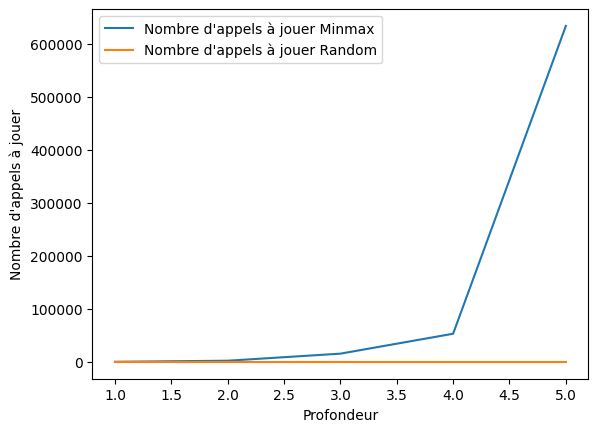

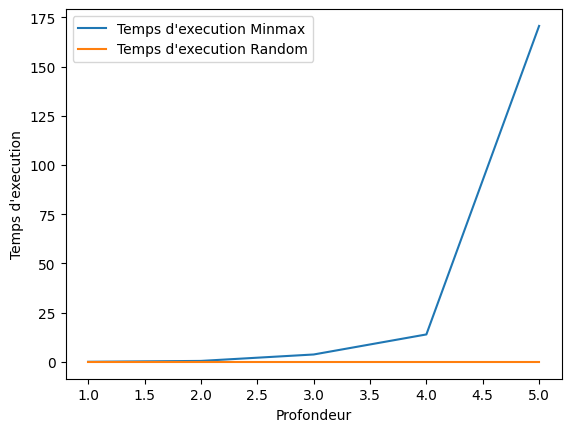

In [16]:
def comparer(joueur1: type = jlib.Random, joueur2: type = jlib.Random, opts1: dict = {}, opts2: dict = {}, profondeurs: list = range(1, 6), label1: str = None, label2: str = None):
    nb_appels = [[], []]
    temps = [[], []]

    for profondeur in profondeurs:
        opts1["profondeur"], opts2["profondeur"] = profondeur, profondeur
        game_instance = jl.Jeu(opts={"interface": False, "choix_joueurs": False})
        game_instance.noir = joueur1(game_instance, "noir", opts=opts1)
        game_instance.blanc = joueur2(game_instance, "blanc", opts=opts2)
        game_instance.joueur_courant = game_instance.noir
        game_instance.run_no_gui()
        nb_appels[0].append(game_instance.noir.nb_appels_jouer)
        nb_appels[1].append(game_instance.blanc.nb_appels_jouer)
        temps[0].append(game_instance.noir.temps_exe)
        temps[1].append(game_instance.blanc.temps_exe)

    plt.plot(profondeurs, nb_appels[0], label="Nombre d'appels à jouer " + joueur1.__name__ if label1 is None else label1)
    plt.plot(profondeurs, nb_appels[1], label="Nombre d'appels à jouer " + joueur2.__name__ if label2 is None else label2)
    plt.xlabel("Profondeur")
    plt.ylabel("Nombre d'appels à jouer")
    plt.legend()
    plt.show()

    plt.plot(profondeurs, temps[0], label="Temps d'execution " + joueur1.__name__ if label1 is None else label1)
    plt.plot(profondeurs, temps[1], label="Temps d'execution " + joueur2.__name__ if label2 is None else label2)
    plt.xlabel("Profondeur")
    plt.ylabel("Temps d'execution")
    plt.legend()
    plt.show()

comparer(jlib.Minmax, jlib.Random)

#### 9. Ajoutez une fonction permettant de simuler n parties entre deux IA, et donnant le nombre de victoires, score moyen ainsi que le temps moyen de calcul pour chaque camp.

In [17]:
def simuler_n_parties(n: int, joueur1, joueur2, profondeur: int = 3):
    victoires_noir, victoires_blanc, num_nuls = 0, 0, 0
    scores_noir, scores_blanc = 0, 0
    nb_appels_noir, nb_appels_blanc = 0, 0
    temps_noir, temps_blanc = 0, 0
    for i in range(n):
        game_instance = jl.Jeu(opts={"interface": False, "choix_joueurs": False})
        game_instance.noir = joueur1(game_instance, "noir", opts={"profondeur": profondeur})
        game_instance.blanc = joueur2(game_instance, "blanc", opts={"profondeur": profondeur})
        game_instance.joueur_courant = game_instance.noir
        game_instance.run_no_gui(verbose=0)
        [v, s_noir, s_blanc] = game_instance.score()
        if v == 1:
            victoires_noir += 1
        elif v == -1:
            victoires_blanc += 1
        else:
            num_nuls += 1
        scores_noir += s_noir
        scores_blanc += s_blanc
        nb_appels_noir += game_instance.noir.nb_appels_jouer
        nb_appels_blanc += game_instance.blanc.nb_appels_jouer
        temps_noir += game_instance.noir.temps_exe
        temps_blanc += game_instance.blanc.temps_exe
    return victoires_noir, victoires_blanc, num_nuls, scores_noir/n, scores_blanc/n, nb_appels_noir/n, nb_appels_blanc/n, temps_noir/n, temps_blanc/n

stats = simuler_n_parties(10, jlib.Minmax, jlib.Random, 4)

col_width = 15
header_width = 50
label_width = header_width - 2 * col_width - 2

print("|" + "-" * header_width + "|")
print(f"|{'':^{label_width}}|{'Noir':^{col_width}}|{'Blanc':^{col_width}}|")
print("|" + "-" * header_width + "|")
print(f"|{'Victoires':^{label_width}}|{stats[0]:^{col_width}}|{stats[1]:^{col_width}}|")
print(f"|{'Nuls':^{label_width}}|{stats[2]:^{col_width}}|{stats[2]:^{col_width}}|")
print(f"|{'Score moyen':^{label_width}}|{stats[3]:^{col_width}}|{stats[4]:^{col_width}}|")
print(f"|{'Nb appels moyen':^{label_width}}|{stats[5]:^{col_width}}|{stats[6]:^{col_width}}|")
print(f"|{'Temps moyen':^{label_width}}|{round(stats[7], 5):^{col_width}}|{round(stats[8], 5):^{col_width}}|")
print("|" + "-" * header_width + "|")


|--------------------------------------------------|
|                  |     Noir      |     Blanc     |
|--------------------------------------------------|
|    Victoires     |       7       |       2       |
|       Nuls       |       1       |       1       |
|   Score moyen    |     37.5      |     26.5      |
| Nb appels moyen  |   140232.1    |      1.0      |
|   Temps moyen    |    30.0921    |     1e-05     |
|--------------------------------------------------|


#### 11.Sans faire l’expérience, quel sera à votre avis le résultat de 100 parties avec Minmax en joueur noir et Alpha-Beta en joueur blanc, et pourquoi ?

A profondeur équivalante, le résultat d'une telle expeeriance serait probablement une victoire de Minmax, car les deux algorithmes doivent renvoyer le même résultat, et dans la configuration proposée, c'est Minmax qui est le premier à jouer, et donc qui a l'avantage.
Il peut cepandant y avoir un ecart de performance significatif entre les deux algorithmes, Alpha-Beta étant normalement plus rapide que Minmax.

#### 12. Comparez les performances de temps avec Minmax, en faisant varier la profondeur maximale.

Victoire de blanc, avec 49 points contre 15.
Victoire de blanc, avec 48 points contre 15.
Victoire de noir, avec 39 points contre 25.
Victoire de blanc, avec 52 points contre 12.
Victoire de blanc, avec 41 points contre 23.


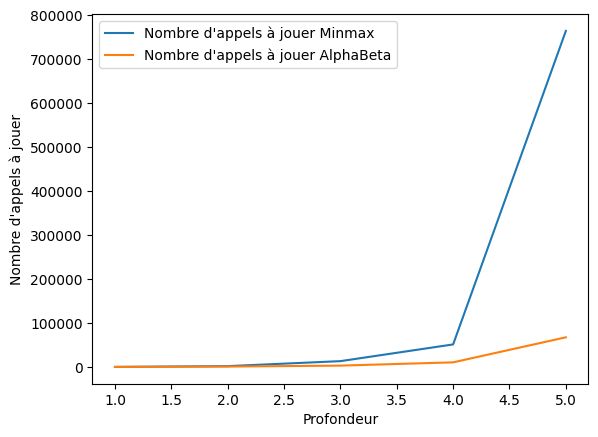

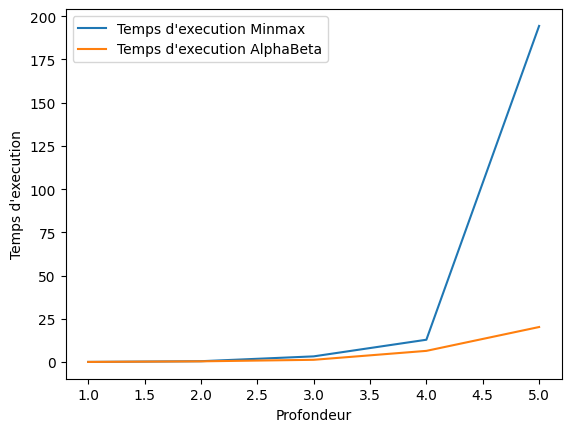

In [18]:
comparer(jlib.Minmax, jlib.AlphaBeta)

#### 14. Faites une nouvelle version d’Alpha-Beta, où depuis un noeud de l’arbre de jeu, le prochain choisi pour l’exploration est le noeud ayant la meilleure valeur selon votre fonction d’évaluation. Comparez cette nouvelle version avec l’ancienne.

la partie est un nul, avec 32 points chacun.
Victoire de noir, avec 47 points contre 17.
Victoire de noir, avec 50 points contre 14.
Victoire de blanc, avec 41 points contre 23.
Victoire de noir, avec 35 points contre 29.


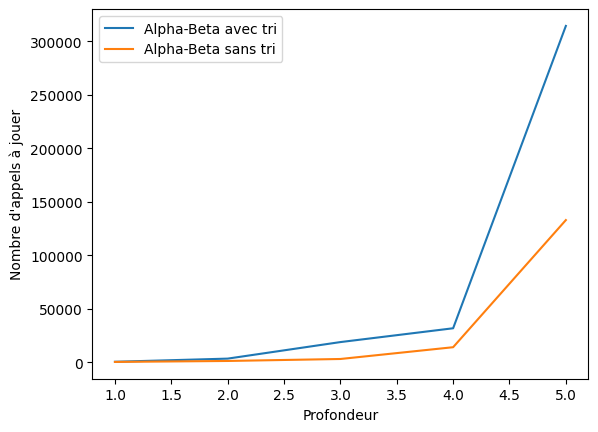

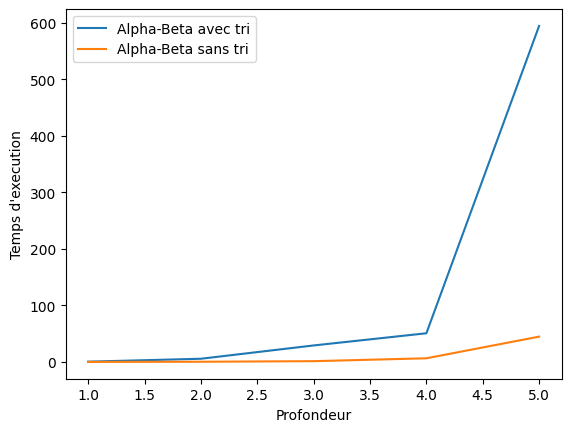

In [21]:
comparer(jlib.AlphaBeta, jlib.AlphaBeta, {"tri": True}, {"tri": False}, label1="Alpha-Beta avec tri", label2="Alpha-Beta sans tri")

#### 15. Définissez une nouvelle fonction d’évaluation pour améliorer votre algorithme. Vous pouvez prendre juger que les coins sont mieux que les bords qui sont mieux que le reste, retirer du score aux cases permettant à l’adversaire d’accéder aux coins, considérer le nombre de coups possibles du joueur ou de son adversaire...

In [23]:
stats = simuler_n_parties(10, jlib.AlphaBeta, jlib.Random, 6)

col_width = 15
header_width = 50
label_width = header_width - 2 * col_width - 2

print("|" + "-" * header_width + "|")
print(f"|{'':^{label_width}}|{'Noir':^{col_width}}|{'Blanc':^{col_width}}|")
print("|" + "-" * header_width + "|")
print(f"|{'Victoires':^{label_width}}|{stats[0]:^{col_width}}|{stats[1]:^{col_width}}|")
print(f"|{'Nuls':^{label_width}}|{stats[2]:^{col_width}}|{stats[2]:^{col_width}}|")
print(f"|{'Score moyen':^{label_width}}|{stats[3]:^{col_width}}|{stats[4]:^{col_width}}|")
print(f"|{'Nb appels moyen':^{label_width}}|{stats[5]:^{col_width}}|{stats[6]:^{col_width}}|")
print(f"|{'Temps moyen':^{label_width}}|{round(stats[7], 5):^{col_width}}|{round(stats[8], 5):^{col_width}}|")
print("|" + "-" * header_width + "|")

|--------------------------------------------------|
|                  |     Noir      |     Blanc     |
|--------------------------------------------------|
|    Victoires     |       9       |       1       |
|       Nuls       |       0       |       0       |
|   Score moyen    |     43.3      |     20.7      |
| Nb appels moyen  |   240296.0    |      1.0      |
|   Temps moyen    |   94.36491    |     1e-05     |
|--------------------------------------------------|
